# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:**  
**Title of the experiment:**  
**Starting date:**  
**Expected enddate:**  
**Partner:**  
**Goal of the experiment:**  
**Research question:**  
**Expectations or Hypothesis:**  
**Desired accuracy:**  




In [1]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 

# Preparation
 


**Assignments:**  

**Method:**  
**Theory:**  
**Independent variable:**  
**Dependent variable:**  
**Controlled variablen:**  
**Measurement instruments \& Settings:**  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

In [137]:
# Measurements: Explain the names of variables provide only raw data in np.arrays!

q = -1.602e-19                       # C
n, u_n = 2.0, 0.1                    # idealiteitsfactor Si
T, u_T = 293.15, 1.0                 # K (kamertemperatuur, pas aan)

# Data

#Voor ingesteld:
R1, R2, R3 = 32.834e3, 0.99729e3, 99.875       # Ohm (Met DMM gemeten)
U_bron = np.array([0.099, 0.248, 0.498, 0.747, 0.997, 1.246, 1.496, 1.746, 1.996, 2.245, 2.496, 2.995, 3.494, 3.993, 4.99, 6.48, 8.98, 13.97, 19.96, 31.94])      # In Volt, gemeten met 3.5 DMM
U_R1    = np.array([0.033e-3, 0.079e-3, 0.187e-3, 0.359e-3, 0.615e-3, 1.035e-3, 1.666e-3, 2.603e-3, 4.032e-3, 6.074e-3, 9.053e-3, 18.620e-3, 33.935e-3, 55.292e-3, 111.8e-3, 216.645e-3, 0.41341, 0.83492, 1.35699, 2.4165])  # In Volt, gemeten met 5.5 DMM


**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**


In [138]:
# Onzekerheden (In handleiding: % aflezing * aflezing + % bereik * bereik + tellen * 1 tel)
#u_Ubron = aflezingUbron * U_bron + tellen      # voorbeeld: 0.5% aflezing + 1 tel
#u_UR    = aflezingUR * U_R + offset        # voorbeeld: 0.02% aflezing + kleine offset
#u_R1    = 0.001 * R1                 # voorbeeld: 0.1%
 
# Verwerking
U  = R3 / (R2 + R3) * U_bron         # spanning over diode + R1
print(U)
U_D = U - U_R1                        # spanning over de diode
print(U_D)
I_D = U_R1 / R1                       # stroom door de diode
print(I_D)
print(len(I_D))
#u_ID = I_D * np.sqrt((u_UR / U_R)**2 + (u_R1 / R1)**2)   # onzekerheid in I_D

[0.00901198 0.02257546 0.04533297 0.06799946 0.09075697 0.11342346
 0.13618098 0.15893849 0.18169601 0.20436249 0.22721104 0.27263504
 0.31805904 0.36348304 0.45424002 0.58987481 0.81744997 1.27168999
 1.81696007 2.90750024]
[0.00897898 0.02249646 0.04514597 0.06764046 0.09014197 0.11238846
 0.13451498 0.15633549 0.17766401 0.19828849 0.21815804 0.25401504
 0.28412404 0.30819104 0.34244002 0.37322981 0.40403997 0.43676999
 0.45997007 0.49100024]
[1.00505573e-09 2.40604252e-09 5.69531583e-09 1.09337881e-08
 1.87305842e-08 3.15222026e-08 5.07400865e-08 7.92775781e-08
 1.22799537e-07 1.84991168e-07 2.75720290e-07 5.67095084e-07
 1.03353231e-06 1.68398611e-06 3.40500700e-06 6.59819090e-06
 1.25909119e-05 2.54285192e-05 4.13288055e-05 7.35974904e-05]
20


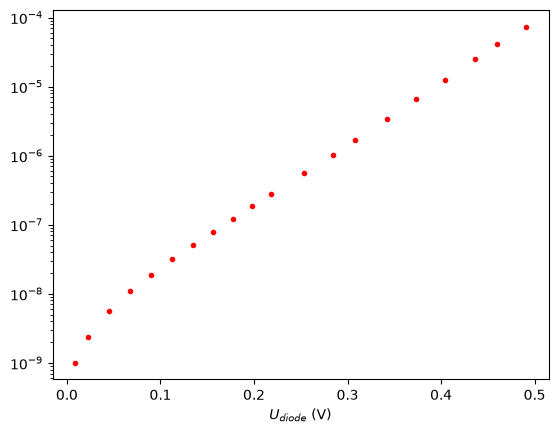

In [139]:
#Data processing and analysis:
plt.figure()
plt.plot(U_D, I_D, 'r.')
plt.xlabel(r'$U_{diode}$ (V)')
plt.yscale('log')



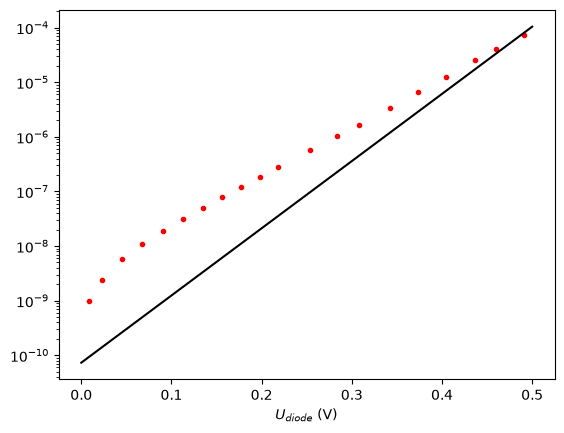

In [141]:
#Data processing and analysis:
#Haal punten onder 0.1 weg
U_D_FIT = U_D[5:]
I_D_FIT = I_D[5:]

def fitfunc(U, I0, c):
    return I0*(np.e**(c*U))

p0 = [1e-10, 40]

fitopt, fitcov = curve_fit(fitfunc, U_D_FIT, I_D_FIT, p0=p0, bounds=([0,0],[1e-3,100]))
xrange = np.linspace(0, 0.5, 100)

I0 = fitopt[0]
c = fitopt[1]

plt.figure()
plt.plot(U_D, I_D, 'r.')
plt.plot(xrange, fitfunc(xrange, I0, c), 'k-')
plt.xlabel(r'$U_{diode}$ (V)')
plt.yscale('log')



helling = 8.910755526194434
snijpunt = -8.502504203485131


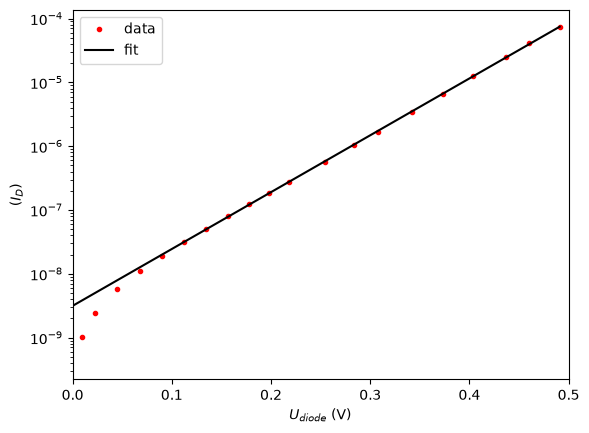

In [142]:
# log10(I_D)
y = np.log10(I_D_FIT)

def linfit(U, a, b):
    return a*U + b

fitopt, fitcov = curve_fit(linfit, U_D_FIT, y)

a = fitopt[0]
b = fitopt[1]

print("helling =", a)
print("snijpunt =", b)

xrange = np.linspace(-0.1, max(U_D_FIT), 100)
plt.figure()
plt.plot(U_D, I_D, 'r.', label='data')
plt.plot(xrange, 10**(linfit(xrange, a, b)), 'k-', label='fit')
plt.xlabel(r'$U_{diode}$ (V)')
plt.ylabel(r'$(I_D)$')
plt.yscale('log')
plt.xlim((0, 0.5))
plt.legend()
plt.show()

**Describing the pattern in the processed data:**  


In [144]:
#Calculations of e.a. measurement uncertainties, and providing final answers.
k_B = -np.log10(np.e) * q / (a * n * T)
print(k_B)

1.331718399803126e-23


**Notes:**  

# Discussion



# Conclusion

# Additional notes, remarks, explanations, thoughts etc